In [5]:
cd ..

/home/users/cornkle/pythonWorkspace/proj_CEH


In [30]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from shared.paths import load_paths
paths = load_paths()

ROOT = Path(paths.cp4_2d) / "CP4_box_JASMIN/mean3h_v2/timeseries"

MONTH = 8
HOURS = [17,18,19]              # change to [17, 18, 19] when all are available
DAYS = 30
BOX_PIXELS = 23


def files_for(label, hour):
    ftag = "hist" if label == "hist" else "fut"
    folder = ROOT / (
        f"SM_sh_lsRain_Aug{MONTH:02d}_{ftag}_{hour:02d}UTC_"
        f"pm{DAYS}d_box{BOX_PIXELS:02d}px"
    )
    return sorted(glob.glob(str(folder / "*_timeseries.nc")))


def get_sm_lag(path):
    with xr.open_dataset(path) as ds:
        sm = np.asarray(ds["SM"].values, float).squeeze()
        lag = np.asarray(ds["lag_hour_SM"].values, float).squeeze()
    return sm, lag


def t0_wetting(path, pre_hours=5, post_hours=5):
    with xr.open_dataset(path) as ds:
        sm = np.asarray(ds["SM"].values, float).squeeze()
        sm_lag = np.asarray(ds["lag_hour_SM"].values, float).squeeze()

        rain = np.asarray(ds["lsRain"].values, float).squeeze()
        rain_lag = np.asarray(ds["lag_hour_lsRain"].values, float).squeeze()

    pre = (sm_lag >= -pre_hours) & (sm_lag <= 0)
    post = (sm_lag >= 0) & (sm_lag <= post_hours)

    if pre.sum() == 0 or post.sum() == 0:
        return np.nan, np.nan, np.nan, np.nan

    sm_pre = np.nanmin(sm[pre])
    sm_post = np.nanmax(sm[post])

    # rainfall at t0
    i0 = np.nanargmin(np.abs(rain_lag))
    rain_t0 = rain[i0]

    return sm_post - sm_pre, sm_pre, sm_post, rain_t0


rows = []

for label in ["hist", "future"]:
    for hour in HOURS:
        files = files_for(label, hour)
        print(label, hour, len(files))

        for f in files:
            wetting, sm_pre, sm_post, rain_t0 = t0_wetting(f)

            # only storms with >= 1 mm h-1 rainfall at t0
            if not np.isfinite(rain_t0) or rain_t0 < 1:
                continue

            rows.append({
                "label": label,
                "hour": hour,
                "file": Path(f).name,
                "rain_t0": rain_t0,
                "t0_wetting": wetting,
                "SM_pre_t0": sm_pre,
                "SM_post_t0": sm_post,
            })

wet = pd.DataFrame(rows)
wet = wet[np.isfinite(wet["t0_wetting"])].copy()

display(wet.head())

hist 17 3505
hist 18 3179
hist 19 2786
future 17 2530
future 18 2332
future 19 2081


,label,hour,file,rain_t0,t0_wetting,SM_pre_t0,SM_post_t0
0,hist,17,1998-08-01_17:00:00_103_lonXlat_[-10.6]_[13.]_...,1.398090,1.861084,11.200139,13.061223
1,hist,17,1998-08-01_17:00:00_104_lonXlat_[2.6]_[13.3]_3...,3.942276,10.281314,7.924443,18.205757
2,hist,17,1998-08-01_17:00:00_115_lonXlat_[15.6]_[14.]_3...,1.608382,3.443957,9.455621,12.899578
3,hist,17,1998-08-01_17:00:00_116_lonXlat_[8.9]_[14.5]_3...,1.181742,4.158844,11.006702,15.165546
4,hist,17,1998-08-01_17:00:00_138_lonXlat_[-0.9]_[16.]_3...,2.992820,8.925779,7.299044,16.224823


In [31]:
percentiles = [1, 5, 10, 20, 25, 50]

for label in ["hist", "future"]:
    vals = wet.loc[wet["label"] == label, "t0_wetting"].dropna()

    print(f"\n{label}: n={len(vals)}")
    for p in percentiles:
        print(f"  p{p:02d}: {np.percentile(vals, p):.3f} kg m-2")

vals = wet["t0_wetting"].dropna()

print(f"\nPOOLED: n={len(vals)}")
for p in percentiles:
    print(f"  p{p:02d}: {np.percentile(vals, p):.3f} kg m-2")


hist: n=7716
  p01: 0.966 kg m-2
  p05: 1.750 kg m-2
  p10: 2.455 kg m-2
  p20: 3.459 kg m-2
  p25: 3.911 kg m-2
  p50: 6.297 kg m-2

future: n=6243
  p01: 1.294 kg m-2
  p05: 2.332 kg m-2
  p10: 3.222 kg m-2
  p20: 4.642 kg m-2
  p25: 5.317 kg m-2
  p50: 8.559 kg m-2

POOLED: n=13959
  p01: 1.042 kg m-2
  p05: 1.986 kg m-2
  p10: 2.725 kg m-2
  p20: 3.886 kg m-2
  p25: 4.410 kg m-2
  p50: 7.173 kg m-2


In [36]:
for threshold in [0.25, 0.5, 1.0, 1.5, 2.5,3.0]:
    print(
        threshold,
        np.mean(wet["t0_wetting"] >= threshold)
    )

0.25 0.9992119779353822
0.5 0.9982090407622323
1.0 0.9914033956587148
1.5 0.974568378823698
2.5 0.9164696611505122
3.0 0.8778565799842396


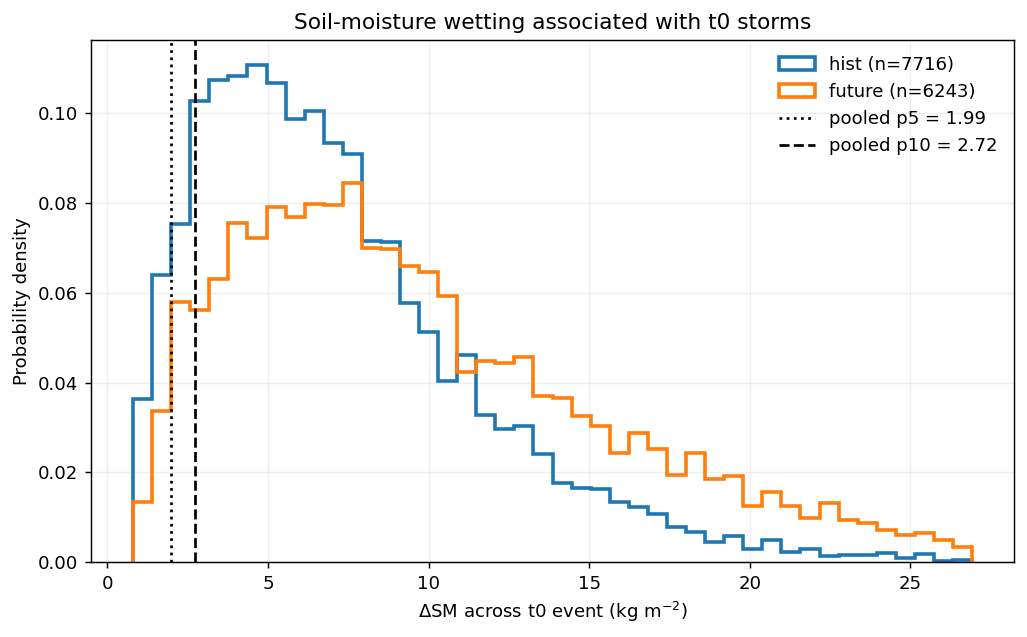

In [39]:
vals = wet["t0_wetting"].dropna()
lo, hi = np.nanpercentile(vals, [0.5, 99.5])
bins = np.linspace(lo, hi, 45)

fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

for label in ["hist", "future"]:
    v = wet.loc[wet["label"] == label, "t0_wetting"].dropna()

    ax.hist(
        v,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        label=f"{label} (n={len(v)})",
    )

ax.axvline(
    np.percentile(vals, 5),
    color="k",
    ls=":",
    lw=1.5,
    label=f"pooled p5 = {np.percentile(vals, 5):.2f}"
)

ax.axvline(
    np.percentile(vals, 10),
    color="k",
    ls="--",
    lw=1.5,
    label=f"pooled p10 = {np.percentile(vals, 10):.2f}"
)

ax.set_xlabel(r"$\Delta$SM across t0 event (kg m$^{-2}$)")
ax.set_ylabel("Probability density")
ax.set_title("Soil-moisture wetting associated with t0 storms")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

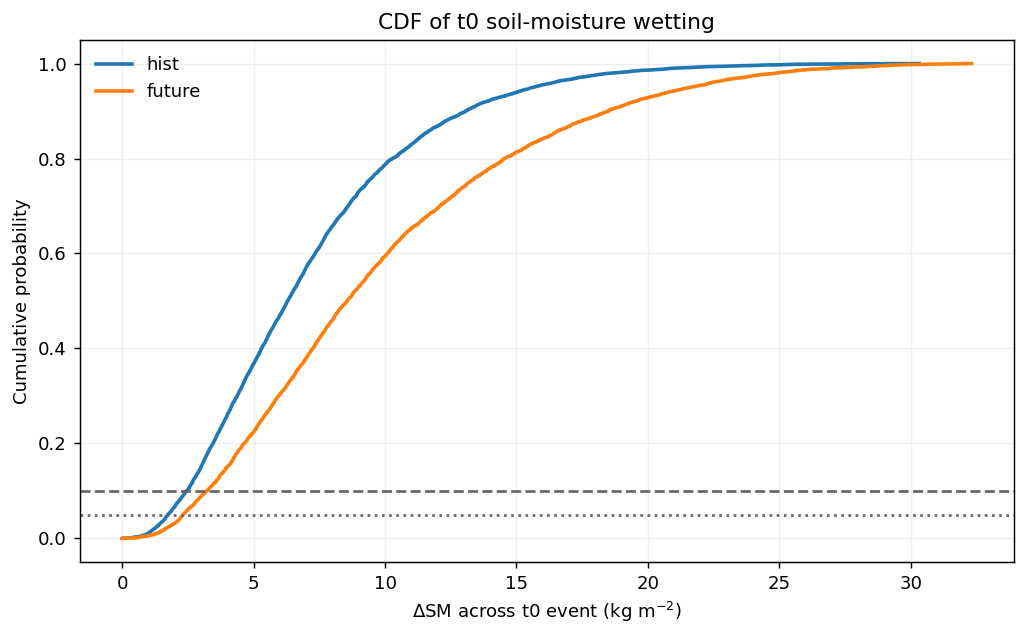

In [40]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

for label in ["hist", "future"]:
    v = np.sort(wet.loc[wet["label"] == label, "t0_wetting"].dropna().values)
    y = np.arange(1, len(v)+1) / len(v)

    ax.plot(v, y, lw=2, label=label)

ax.axhline(0.05, color="0.4", ls=":")
ax.axhline(0.10, color="0.4", ls="--")

ax.set_xlabel(r"$\Delta$SM across t0 event (kg m$^{-2}$)")
ax.set_ylabel("Cumulative probability")
ax.set_title("CDF of t0 soil-moisture wetting")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [53]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from shared.paths import load_paths
paths = load_paths()

ROOT = Path(paths.cp4_2d) / "CP4_box_JASMIN/mean3h_v2/timeseries"

MONTH = 8
HOURS = [17,18,19]       # later [17, 18, 19]
DAYS = 30
BOX_PIXELS = 23


def files_for(label, hour):
    ftag = "hist" if label == "hist" else "fut"
    folder = ROOT / (
        f"SM_sh_lsRain_Aug{MONTH:02d}_{ftag}_{hour:02d}UTC_"
        f"pm{DAYS}d_box{BOX_PIXELS:02d}px"
    )
    return sorted(glob.glob(str(folder / "*_timeseries.nc")))


def event_response(path, pre_hours=5, post_hours=5):
    with xr.open_dataset(path) as ds:
        sm = np.asarray(ds["SM"].values, float).squeeze()
        sm_lag = np.asarray(ds["lag_hour_SM"].values, float).squeeze()

        sh = np.asarray(ds["sh_anom"].values, float).squeeze()
        sh_lag = np.asarray(ds["lag_hour_sh"].values, float).squeeze()

        rain = np.asarray(ds["lsRain"].values, float).squeeze()
        rain_lag = np.asarray(ds["lag_hour_lsRain"].values, float).squeeze()

    # SM wetting: minimum before -> settled maximum after
    pre_sm = (sm_lag >= -pre_hours) & (sm_lag <= 0)
    post_sm = (sm_lag >= 0) & (sm_lag <= post_hours)

    sm_pre = np.nanmin(sm[pre_sm])
    sm_post = np.nanmax(sm[post_sm])
    dSM = sm_post - sm_pre

    # SH anomaly response: removes mean diurnal cycle
    pre_sh = (sh_lag >= -pre_hours) & (sh_lag <= 0)
    post_sh = (sh_lag >= 0) & (sh_lag <= post_hours)

    sh_pre = np.nanmean(sh[pre_sh])
    sh_post = np.nanmean(sh[post_sh])
    dSH = sh_post - sh_pre

    # Rain at t0
    i0 = np.nanargmin(np.abs(rain_lag))
    rain_t0 = rain[i0]

    return sm_pre, sm_post, dSM, sh_pre, sh_post, dSH, rain_t0
    

rows = []

for label in ["hist", "future"]:
    for hour in HOURS:
        files = files_for(label, hour)
        print(label, hour, len(files))

        for f in files:
            sm_pre, sm_post, dSM, sh_pre, sh_post, dSH, rain_t0 = event_response(f)

            # Your existing minimum-rainfall sample
            if not np.isfinite(rain_t0) or rain_t0 < 1:
                continue

            rows.append({
                "label": label,
                "hour": hour,
                "file": Path(f).name,
                "rain_t0": rain_t0,
                "SM_pre": sm_pre,
                "SM_post": sm_post,
                "dSM": dSM,
                "SH_pre": sh_pre,
                "SH_post": sh_post,
                "dSH": dSH,
                
            })

event = pd.DataFrame(rows)
event = event[np.isfinite(event["dSM"]) & np.isfinite(event["dSH"])].copy()

display(event.head())

hist 17 3505
hist 18 3179
hist 19 2786
future 17 2530
future 18 2332
future 19 2081


,label,hour,file,rain_t0,SM_pre,SM_post,dSM,SH_pre,SH_post,dSH
0,hist,17,1998-08-01_17:00:00_103_lonXlat_[-10.6]_[13.]_...,1.398090,11.200139,13.061223,1.861084,1.296871,-1.761682,-3.058553
1,hist,17,1998-08-01_17:00:00_104_lonXlat_[2.6]_[13.3]_3...,3.942276,7.924443,18.205757,10.281314,-9.262108,6.955801,16.217909
2,hist,17,1998-08-01_17:00:00_115_lonXlat_[15.6]_[14.]_3...,1.608382,9.455621,12.899578,3.443957,-30.893370,-0.180761,30.712609
3,hist,17,1998-08-01_17:00:00_116_lonXlat_[8.9]_[14.5]_3...,1.181742,11.006702,15.165546,4.158844,-33.607375,5.503648,39.111024
4,hist,17,1998-08-01_17:00:00_138_lonXlat_[-0.9]_[16.]_3...,2.992820,7.299044,16.224823,8.925779,-52.966653,5.861470,58.828123


KeyError: 'rain_m5_p5'

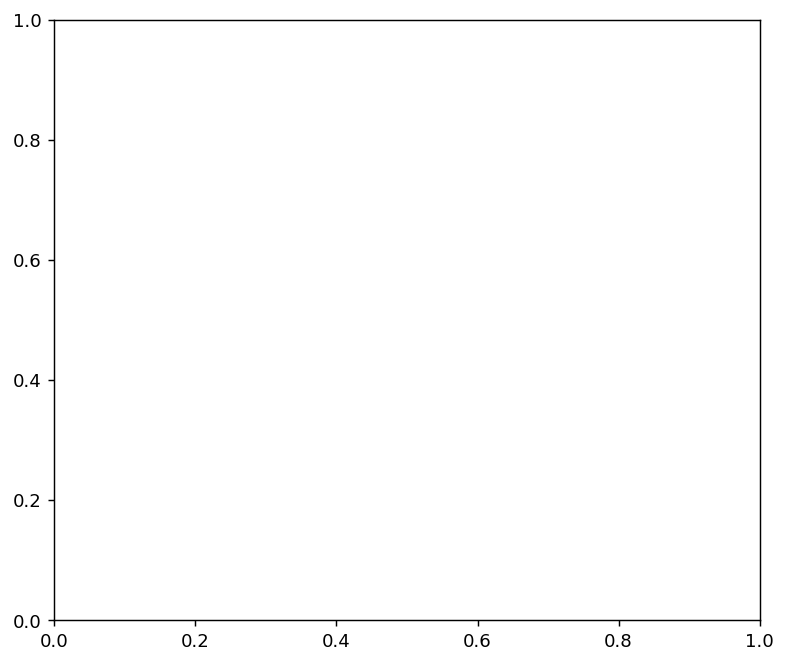

In [55]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=130)

for label in ["hist", "future"]:
    sub = event[event["label"] == label]

    ax.scatter(
        sub["rain_m5_p5"],
        sub["dSM"],
        s=15,
        alpha=0.3,
        label=label,
    )

ax.axhline(2, color="k", ls="--", lw=1.5,
           label=r"$\Delta$SM = 2 kg m$^{-2}$")

ax.set_xlabel("Rain accumulation t0−5 to t0+5 (mm)")
ax.set_ylabel(r"SM increase (kg m$^{-2}$)")
ax.set_title("Rainfall associated with storm-scale soil wetting")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [43]:
wet2 = event[event["dSM"] >= 2.5].copy()

for label in ["hist", "future"]:
    vals = wet2.loc[wet2["label"] == label, "rain_m5_p5"].dropna()

    print(f"\n{label}: ΔSM >= 2.5 kg m-2, n={len(vals)}")

    for p in [5, 10, 25, 50, 75, 90, 95]:
        print(f"p{p:02d}: {np.percentile(vals, p):.2f} mm")

    print(f"max: {np.max(vals):.2f} mm")


hist: ΔSM >= 2.5 kg m-2, n=7482
p05: 5.54 mm
p10: 6.66 mm
p25: 9.34 mm
p50: 14.33 mm
p75: 22.05 mm
p90: 32.28 mm
p95: 39.52 mm
max: 110.95 mm

future: ΔSM >= 2.5 kg m-2, n=6107
p05: 6.68 mm
p10: 8.40 mm
p25: 12.82 mm
p50: 20.88 mm
p75: 34.68 mm
p90: 53.38 mm
p95: 65.12 mm
max: 209.02 mm


In [44]:
vals = wet2["rain_m5_p5"].dropna()

print("\nPooled rainfall for ΔSM >= 2 kg m-2:")
for p in [1, 5, 10, 25, 50, 75, 90, 95]:
    print(f"p{p:02d}: {np.percentile(vals, p):.2f} mm")


Pooled rainfall for ΔSM >= 2 kg m-2:
p01: 4.58 mm
p05: 5.87 mm
p10: 7.17 mm
p25: 10.57 mm
p50: 16.80 mm
p75: 27.46 mm
p90: 42.23 mm
p95: 54.73 mm


In [46]:
for rain_thresh in [1, 2, 3, 5, 7.5, 10, 15, 20]:
    sub = event[event["rain_m5_p5"] >= rain_thresh]

    if len(sub) == 0:
        continue

    frac = np.mean(sub["dSM"] >= 2.5)

    print(
        f"Rain >= {rain_thresh:4.1f} mm: "
        f"n={len(sub):5d}, "
        f"{frac*100:5.1f}% have ΔSM >= 2.5"
    )

Rain >=  1.0 mm: n=16190,  83.9% have ΔSM >= 2.5
Rain >=  2.0 mm: n=15817,  85.9% have ΔSM >= 2.5
Rain >=  3.0 mm: n=15362,  88.5% have ΔSM >= 2.5
Rain >=  5.0 mm: n=14162,  94.0% have ΔSM >= 2.5
Rain >=  7.5 mm: n=12440,  97.0% have ΔSM >= 2.5
Rain >= 10.0 mm: n=10725,  98.3% have ΔSM >= 2.5
Rain >= 15.0 mm: n= 7746,  99.1% have ΔSM >= 2.5
Rain >= 20.0 mm: n= 5497,  99.4% have ΔSM >= 2.5


In [24]:
for label in ["hist", "future"]:
    print(f"\n{label.upper()}")

    base = event[event["label"] == label]

    for rain_thresh in [1, 2, 3, 5, 8, 10, 15, 20]:
        sub = base[base["rain_m5_p5"] >= rain_thresh]

        if len(sub) == 0:
            continue

        frac = np.mean(sub["dSM"] >= 2)

        print(
            f"Rain >= {rain_thresh:4.1f} mm: "
            f"n={len(sub):5d}, "
            f"{frac*100:5.1f}% have ΔSM >= 2"
        )


HIST
Rain >=  1.0 mm: n= 9341,  84.9% have ΔSM >= 2
Rain >=  2.0 mm: n= 9089,  87.3% have ΔSM >= 2
Rain >=  3.0 mm: n= 8764,  90.5% have ΔSM >= 2
Rain >=  5.0 mm: n= 7896,  95.3% have ΔSM >= 2
Rain >=  8.0 mm: n= 6418,  98.2% have ΔSM >= 2
Rain >= 10.0 mm: n= 5462,  99.0% have ΔSM >= 2
Rain >= 15.0 mm: n= 3548,  99.7% have ΔSM >= 2
Rain >= 20.0 mm: n= 2274,  99.7% have ΔSM >= 2

FUTURE
Rain >=  1.0 mm: n= 6849,  92.5% have ΔSM >= 2
Rain >=  2.0 mm: n= 6728,  94.1% have ΔSM >= 2
Rain >=  3.0 mm: n= 6598,  95.9% have ΔSM >= 2
Rain >=  5.0 mm: n= 6266,  98.1% have ΔSM >= 2
Rain >=  8.0 mm: n= 5675,  99.0% have ΔSM >= 2
Rain >= 10.0 mm: n= 5263,  99.3% have ΔSM >= 2
Rain >= 15.0 mm: n= 4198,  99.6% have ΔSM >= 2
Rain >= 20.0 mm: n= 3223,  99.7% have ΔSM >= 2


In [25]:
dsm_bins = [0, 1, 2, 3, 4, 5, 6, 8, 10]
event["dSM_bin"] = pd.cut(event["dSM"], bins=dsm_bins)

rain_for_dsm = (
    event.groupby(["label", "dSM_bin"], observed=True)
    .agg(
        rain_median=("rain_m5_p5", "median"),
        rain_p25=("rain_m5_p5", lambda x: np.nanpercentile(x, 25)),
        rain_p75=("rain_m5_p5", lambda x: np.nanpercentile(x, 75)),
        dSM_median=("dSM", "median"),
        n=("rain_m5_p5", "size"),
    )
    .reset_index()
)

display(rain_for_dsm)


,label,dSM_bin,rain_median,rain_p25,rain_p75,dSM_median,n
0,future,"(0, 1]",1.537073,0.926824,2.438752,0.553298,248
1,future,"(1, 2]",3.687835,2.770339,5.836611,1.514059,327
2,future,"(2, 3]",5.533383,4.449813,9.047322,2.484112,445
3,future,"(3, 4]",7.609089,6.182408,11.525942,3.545606,450
4,future,"(4, 5]",9.660750,7.936762,14.603533,4.451799,492
5,future,"(5, 6]",11.872101,9.643383,17.869734,5.490490,527
6,future,"(6, 8]",15.345615,12.252693,23.372202,7.031543,1007
7,future,"(8, 10]",19.796956,15.865682,27.601038,8.947854,850
8,hist,"(0, 1]",1.962402,1.323922,3.116477,0.556025,602
9,hist,"(1, 2]",4.074307,3.043926,5.903050,1.489816,880


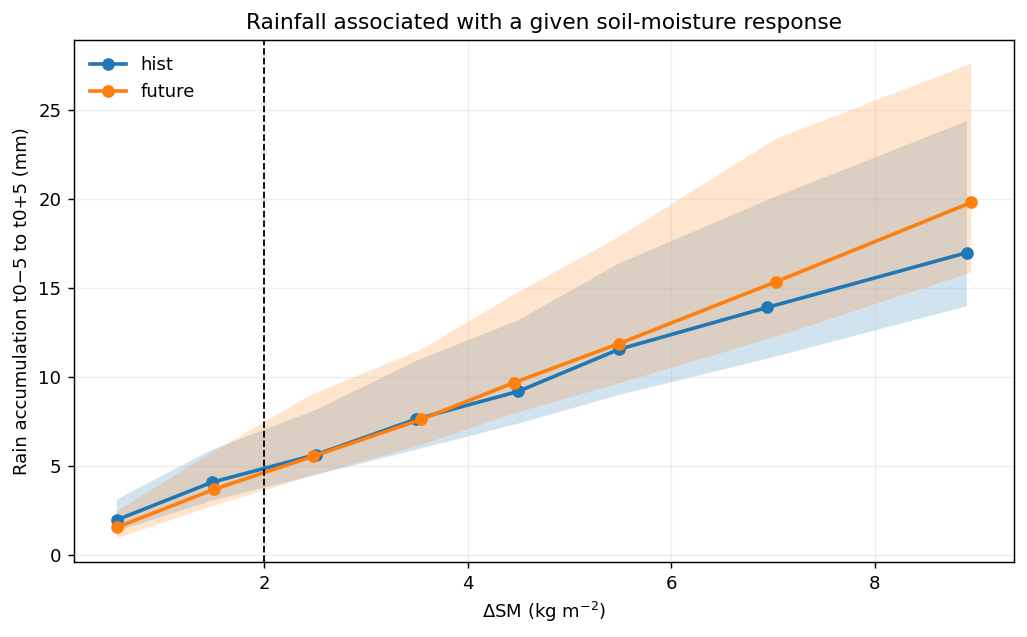

In [26]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

for label in ["hist", "future"]:
    s = rain_for_dsm[rain_for_dsm["label"] == label]

    ax.plot(
        s["dSM_median"],
        s["rain_median"],
        marker="o",
        lw=2,
        label=label,
    )

    ax.fill_between(
        s["dSM_median"],
        s["rain_p25"],
        s["rain_p75"],
        alpha=0.2,
    )

ax.axvline(2, color="k", ls="--", lw=1)

ax.set_xlabel(r"$\Delta$SM (kg m$^{-2}$)")
ax.set_ylabel("Rain accumulation t0−5 to t0+5 (mm)")
ax.set_title("Rainfall associated with a given soil-moisture response")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [27]:
lo, hi = 1.75, 2.25

for label in ["hist", "future"]:
    sub = event[
        (event["label"] == label) &
        (event["dSM"] >= lo) &
        (event["dSM"] < hi)
    ]

    print(f"\n{label.upper()} ΔSM={lo}-{hi} kg m-2, n={len(sub)}")
    print(f"median rain: {sub['rain_m5_p5'].median():.2f} mm")
    print(f"mean rain:   {sub['rain_m5_p5'].mean():.2f} mm")
    print(
        "IQR rain:    "
        f"{sub['rain_m5_p5'].quantile(0.25):.2f} - "
        f"{sub['rain_m5_p5'].quantile(0.75):.2f} mm"
    )


HIST ΔSM=1.75-2.25 kg m-2, n=458
median rain: 4.88 mm
mean rain:   5.91 mm
IQR rain:    3.83 - 6.98 mm

FUTURE ΔSM=1.75-2.25 kg m-2, n=182
median rain: 4.71 mm
mean rain:   6.48 mm
IQR rain:    3.83 - 7.48 mm


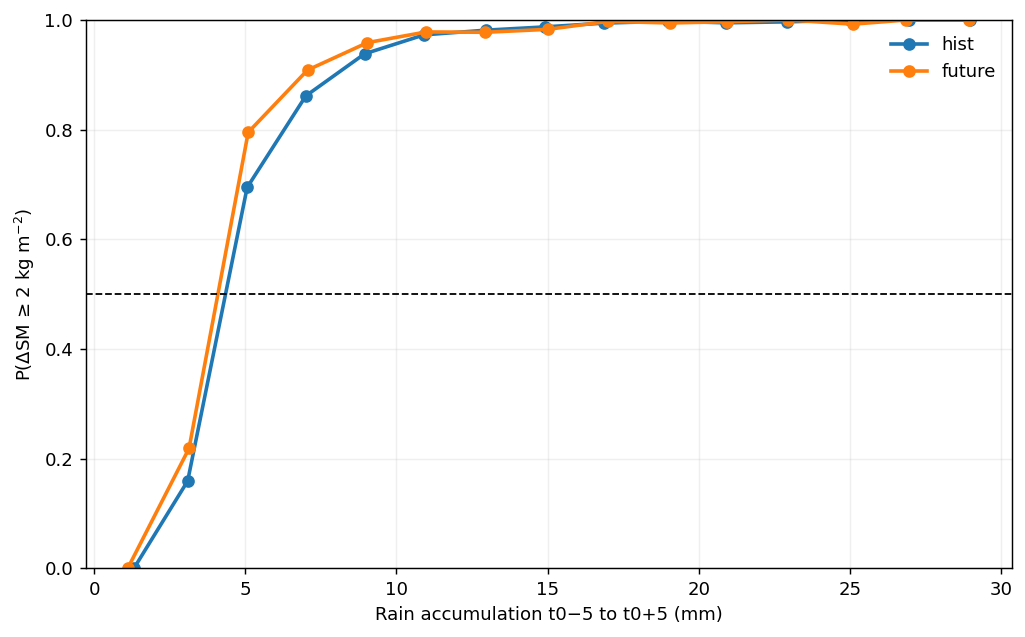

In [29]:
rain_bins = np.arange(0, 32, 2)

event["rain_bin"] = pd.cut(event["rain_m5_p5"], rain_bins)

prob_bin = (
    event.groupby(["label", "rain_bin"], observed=True)
    .agg(
        rain=("rain_m5_p5", "median"),
        probability=("dSM", lambda x: np.mean(x >= 2)),
        n=("dSM", "size"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

for label in ["hist", "future"]:
    s = prob_bin[
        (prob_bin["label"] == label) &
        (prob_bin["n"] >= 20)
    ]

    ax.plot(
        s["rain"],
        s["probability"],
        marker="o",
        lw=2,
        label=label,
    )

ax.axhline(0.5, color="k", ls="--", lw=1)
ax.set_xlabel("Rain accumulation t0−5 to t0+5 (mm)")
ax.set_ylabel(r"P($\Delta$SM ≥ 2 kg m$^{-2}$)")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [48]:
dsm_bins = np.arange(0, 8.5, 0.5)

event["dSM_bin"] = pd.cut(event["dSM"], bins=dsm_bins)

sh_by_sm = (
    event.groupby(["label", "dSM_bin"], observed=True)
    .agg(
        dSM_median=("dSM", "median"),
        dSH_median=("dSH", "median"),
        dSH_p25=("dSH", lambda x: np.nanpercentile(x, 25)),
        dSH_p75=("dSH", lambda x: np.nanpercentile(x, 75)),
        n=("dSH", "size"),
    )
    .reset_index()
)

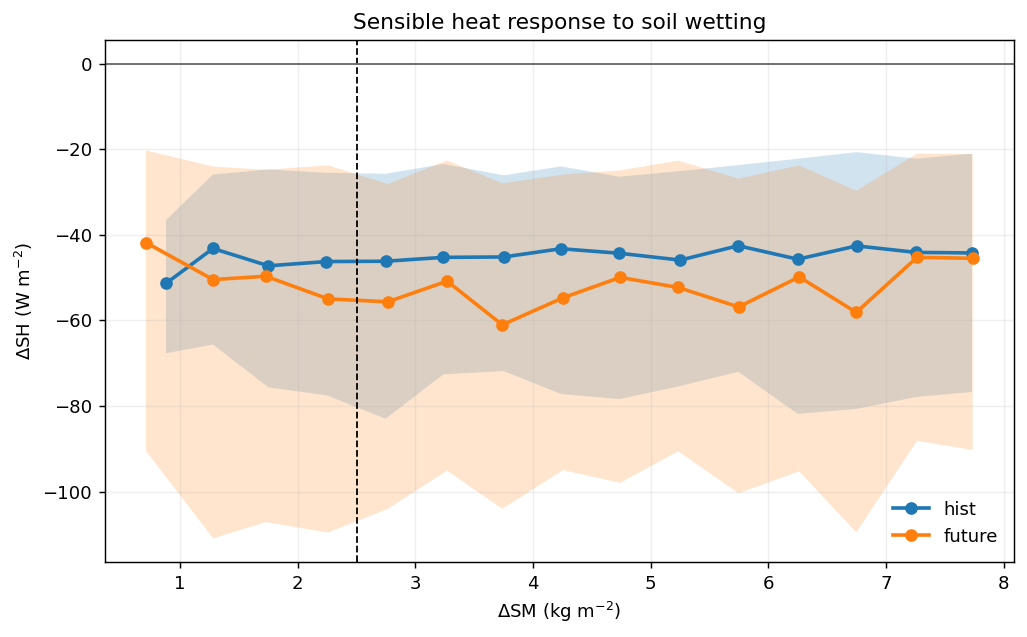

In [54]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

for label in ["hist", "future"]:
    s = sh_by_sm[
        (sh_by_sm["label"] == label) &
        (sh_by_sm["n"] >= 20)
    ]

    ax.plot(
        s["dSM_median"],
        s["dSH_median"],
        marker="o",
        lw=2,
        label=label,
    )

    ax.fill_between(
        s["dSM_median"],
        s["dSH_p25"],
        s["dSH_p75"],
        alpha=0.2,
    )

ax.axvline(2.5, color="k", ls="--", lw=1)
ax.axhline(0, color="0.4", lw=1)

ax.set_xlabel(r"$\Delta$SM (kg m$^{-2}$)")
ax.set_ylabel(r"$\Delta$SH (W m$^{-2}$)")
ax.set_title("Sensible heat response to soil wetting")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [50]:
SM_TARGET = 2.5
SM_HALF_WIDTH = 0.25

sel = event[
    (event["dSM"] >= SM_TARGET - SM_HALF_WIDTH) &
    (event["dSM"] <  SM_TARGET + SM_HALF_WIDTH)
].copy()

print(sel.groupby("label")["dSH"].agg(["count", "mean", "median", "std"]))

        count       mean     median        std
label                                         
future    174 -69.978633 -52.907439  58.357692
hist      317 -58.102613 -46.081330  44.835773


In [51]:
for label in ["hist", "future"]:
    vals = sel.loc[sel["label"] == label, "dSH"].dropna()

    print(f"\n{label.upper()}, ΔSM = {SM_TARGET-SM_HALF_WIDTH:.2f}–{SM_TARGET+SM_HALF_WIDTH:.2f}")
    print(f"n = {len(vals)}")

    for p in [5, 10, 25, 50, 75, 90, 95]:
        print(f"p{p:02d}: {np.percentile(vals, p):.2f} W m-2")


HIST, ΔSM = 2.25–2.75
n = 317
p05: -150.53 W m-2
p10: -120.10 W m-2
p25: -79.71 W m-2
p50: -46.08 W m-2
p75: -25.71 W m-2
p90: -10.93 W m-2
p95: -5.97 W m-2

FUTURE, ΔSM = 2.25–2.75
n = 174
p05: -190.61 W m-2
p10: -146.01 W m-2
p25: -105.05 W m-2
p50: -52.91 W m-2
p75: -23.63 W m-2
p90: -6.61 W m-2
p95: -2.22 W m-2


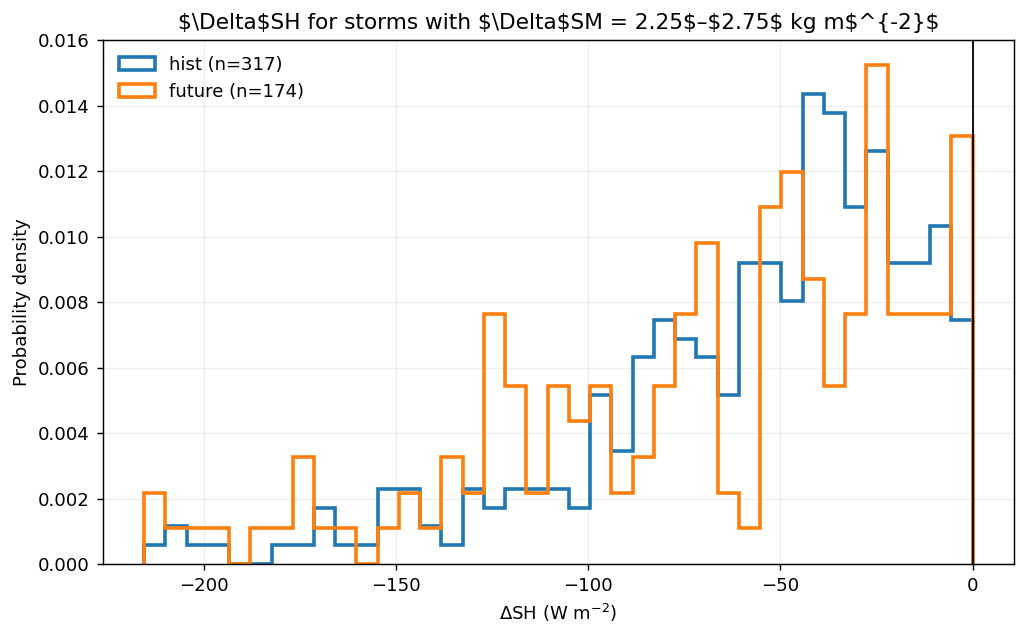

In [52]:
vals = sel["dSH"].dropna()
lo, hi = np.nanpercentile(vals, [1, 99])
bins = np.linspace(lo, hi, 40)

fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

for label in ["hist", "future"]:
    v = sel.loc[sel["label"] == label, "dSH"].dropna()

    ax.hist(
        v,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        label=f"{label} (n={len(v)})",
    )

ax.axvline(0, color="k", lw=1)

ax.set_xlabel(r"$\Delta$SH (W m$^{-2}$)")
ax.set_ylabel("Probability density")
ax.set_title(
    r"$\Delta$SH for storms with "
    rf"$\Delta$SM = {SM_TARGET-SM_HALF_WIDTH:.2f}$–"
    rf"${SM_TARGET+SM_HALF_WIDTH:.2f}$ kg m$^{{-2}}$"
)

ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
dsm_bins = np.arange(0, 8.5, 0.5)
event["dSM_bin"] = pd.cut(event["dSM"], bins=dsm_bins)

sh_by_sm = (
    event.groupby(["label", "dSM_bin"], observed=True)
    .agg(
        dSM_median=("dSM", "median"),
        SHpost_median=("SH_post", "median"),
        SHpost_p25=("SH_post", lambda x: np.nanpercentile(x, 25)),
        SHpost_p75=("SH_post", lambda x: np.nanpercentile(x, 75)),
        dSH_median=("dSH", "median"),
        n=("dSM", "size"),
    )
    .reset_index()
)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

for label in ["hist", "future"]:
    s = sh_by_sm[
        (sh_by_sm["label"] == label) &
        (sh_by_sm["n"] >= 20)
    ]

    ax.plot(
        s["dSM_median"],
        s["SHpost_median"],
        marker="o",
        lw=2,
        label=label,
    )

    ax.fill_between(
        s["dSM_median"],
        s["SHpost_p25"],
        s["SHpost_p75"],
        alpha=0.2,
    )

ax.axvline(2.5, color="k", ls="--", lw=1)
ax.axhline(0, color="0.4", lw=1)

ax.set_xlabel(r"$\Delta$SM (kg m$^{-2}$)")
ax.set_ylabel(r"Post-event SH anomaly (W m$^{-2}$)")
ax.set_title("Sensible heat suppression following soil wetting")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()